# Behind GoEmotions: results analysis and explainability

This third and final notebook is dedicated to the critical evaluation and interpretation of the four architectures (*Logistic Regression, MLP, BiLSTM, Transformer from Scratch*) on the test set. The overall goal is to go beyond pure quantitative analysis to understand the robustness, biases, and decision-making mechanisms of the trained models.

## Notebook objectives

1. **Global evaluation**: compare Accuracy, Micro-F1, and Macro-F1 via comparative charts to verify whether there is a performance gain as model complexity increases.
2. **Class-disaggregated analysis**: study the relationship between emotion frequency and classification quality through Precision, Recall, and F1-Score heatmaps, observing the penalty on rare classes.
3. **Explainable AI**: compare the Transformer predictions with the MLP via the **SHAP** library to quantify the continuous weight attribution and the impact of each individual token on the output.

In [1]:
import os, sys
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/Behind_GoEmotions'
except Exception:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

TRANSFORMER_PATH = os.path.join(PROJECT_ROOT, 'experiments', 'transformer')
if TRANSFORMER_PATH not in sys.path:
    sys.path.append(TRANSFORMER_PATH)

os.chdir(PROJECT_ROOT)
print("PROJECT_ROOT:", PROJECT_ROOT)

Mounted at /content/drive
PROJECT_ROOT: /content/drive/MyDrive/Behind_GoEmotions


In [2]:
# libraries import

import numpy as np
import pandas as pd
import scipy.sparse as sp
import json

import matplotlib.pyplot as plt
import seaborn as sns

import random
from datetime import date
import re as _re

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from transformer_layers import PositionalEmbedding, EncoderBlock

from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
import warnings
warnings.filterwarnings('ignore')

import shap
import logging
logging.getLogger('shap').setLevel(logging.WARNING)
from IPython.display import HTML, display

In [3]:
# project folder paths
DATA_PATH = PROJECT_ROOT + '/data/processed'
VECTORIZED_PATH = DATA_PATH + '/vectorized'
EXPERIMENTS_PATH =  PROJECT_ROOT + '/experiments'
RESULTS_PATH = PROJECT_ROOT + '/results'
COMPARISON_PATH = RESULTS_PATH + '/comparison'
LINEAR_PATH = EXPERIMENTS_PATH + '/tfidf_linear'
MLP_PATH = EXPERIMENTS_PATH + '/tfidf_mlp'
BILSTM_PATH = EXPERIMENTS_PATH + '/bilstm'
TRANSFORMER_PATH = EXPERIMENTS_PATH + '/transformer'

In [4]:
SEED = 42

# environment variables for reproducibility
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CUDNN_DETERMINISTIC"] = "1"

def set_reproducibility(seed=SEED):
    """Set all relevant random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()

set_reproducibility()

# constants
BATCH_SIZE = 128
SEQ_LEN = 128
VOCAB_SIZE = 2500

In [5]:
# to run experiments with different project versions, replace with the desired date "YYYY-MM-DD"
date = "2026-06-06"
print(f"Experiment with models trained on {date}")

Experiment with models trained on 2026-06-06


In [6]:
# load data from csv
# reset index to avoid index misalignment
df_train = pd.read_csv(os.path.join(DATA_PATH, 'df_train.csv')).reset_index(drop=True)
df_val = pd.read_csv(os.path.join(DATA_PATH, 'df_val.csv')).reset_index(drop=True)
df_test = pd.read_csv(os.path.join(DATA_PATH, 'df_test.csv')).reset_index(drop=True)

In [7]:
# handle any NAs
X_train = df_train["processed_text"].fillna('').astype(str).values
X_val = df_val["processed_text"].fillna('').astype(str).values
X_test = df_test["processed_text"].fillna('').astype(str).values

y_train = df_train["label_id"]
y_val = df_val["label_id"]
y_test = df_test["label_id"]

In [8]:
# label encoding
label_names = sorted(df_train["label"].unique())
NUM_CLASSES = len(label_names)

label_to_id = {label: idx for idx, label in enumerate(label_names)}
id_to_label = {idx: label for label, idx in label_to_id.items()}

## Loading models and computing predictions
In this section we reload the models and the vectorized test data.
Since the four architectures accept different input formats, we use two distinct vectorizations, consistent with the previous training phase.

To be able to visualize the results, we prepare two separate dataframes to handle aggregate and disaggregated metrics.

In [9]:
# load models
tfidf_linear = tf.keras.models.load_model(LINEAR_PATH + f'/checkpoints/{date}_tfidf_linear.keras')
tfidf_mlp    = tf.keras.models.load_model(MLP_PATH    + f'/checkpoints/{date}_tfidf_mlp.keras')
bilstm       = tf.keras.models.load_model(BILSTM_PATH + f'/checkpoints/{date}_bilstm.keras')
transformer = tf.keras.models.load_model(
    TRANSFORMER_PATH + f'/checkpoints/{date}_transformer.keras',
    custom_objects={
        'PositionalEmbedding': PositionalEmbedding,
        'EncoderBlock': EncoderBlock,
    }
)

In [10]:
# load vectorized test data
tfidf_data = np.load(os.path.join(VECTORIZED_PATH, "tfidf_arrays.npz"))
X_train_tfidf = tfidf_data["X_train_tfidf"]
X_val_tfidf = tfidf_data["X_val_tfidf"]
X_test_tfidf = tfidf_data["X_test_tfidf"]

int_data = np.load(os.path.join(VECTORIZED_PATH, "int_arrays.npz"))
X_train_int = int_data["X_train_int"]
X_val_int = int_data["X_val_int"]
X_test_int = int_data["X_test_int"]

In [11]:
# compute predictions
y_prob_linear = tfidf_linear.predict(X_test_tfidf, batch_size=BATCH_SIZE)
y_prob_mlp    = tfidf_mlp.predict(X_test_tfidf, batch_size=BATCH_SIZE)

y_prob_bilstm = bilstm.predict(X_test_int, batch_size=BATCH_SIZE)
y_prob_trans  = transformer.predict(X_test_int, batch_size=BATCH_SIZE)

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 158ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 518ms/step


In [12]:
# final evaluation: collect aggregate metrics (D1) and per-class metrics (D2)

all_metrics   = []
all_per_class = []

models_info = {
    'tfidf_linear': (y_prob_linear, LINEAR_PATH),
    'tfidf_mlp':    (y_prob_mlp,    MLP_PATH),
    'bilstm':       (y_prob_bilstm, BILSTM_PATH),
    'transformer':  (y_prob_trans,  TRANSFORMER_PATH),
}

for model_name, (y_prob, path) in models_info.items():
    y_pred = np.argmax(y_prob, axis=1)

    # aggregate metrics
    row = {
        'model':    model_name,
        'accuracy': accuracy_score(y_test, y_pred),
        'micro_f1': f1_score(y_test, y_pred, average='micro', zero_division=0),
        'macro_f1': f1_score(y_test, y_pred, average='macro', zero_division=0),
    }
    all_metrics.append(row)

    # per-class metrics
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, y_pred, labels=np.arange(NUM_CLASSES), zero_division=0
    )
    per_class = pd.DataFrame({
        'model':     model_name,
        'label':     [id_to_label[i] for i in range(NUM_CLASSES)],
        'support':   support,
        'precision': precision,
        'recall':    recall,
        'f1':        f1,
    })
    all_per_class.append(per_class)
    per_class.to_csv(os.path.join(path, 'logs', f'test_per_class_{model_name}.csv'), index=False)

metrics_df   = pd.DataFrame(all_metrics).sort_values('macro_f1', ascending=False).reset_index(drop=True)
per_class_df = pd.concat(all_per_class, ignore_index=True)

metrics_df.to_csv(os.path.join(COMPARISON_PATH, f'{date}_test_metrics.csv'), index=False)
display(metrics_df.round(4))

,model,accuracy,micro_f1,macro_f1
0,tfidf_mlp,0.4691,0.4691,0.4031
1,tfidf_linear,0.3898,0.3898,0.3125
2,transformer,0.4320,0.4320,0.2971
3,bilstm,0.4218,0.4218,0.2859


In [13]:
# save per-sample test-set predictions for all four models
# produces a single CSV with the original text, true label, and each model's predicted label
pred_df = df_test[['comment_text', 'label']].copy()
pred_df['true_label_id'] = y_test.values

pred_df['pred_tfidf_linear'] = np.argmax(y_prob_linear, axis=1)
pred_df['pred_tfidf_mlp']    = np.argmax(y_prob_mlp,    axis=1)
pred_df['pred_bilstm']       = np.argmax(y_prob_bilstm, axis=1)
pred_df['pred_transformer']  = np.argmax(y_prob_trans,  axis=1)

# map integer ids back to label strings for readability
for col in ['pred_tfidf_linear', 'pred_tfidf_mlp', 'pred_bilstm', 'pred_transformer']:
    pred_df[col] = pred_df[col].map(id_to_label)

pred_csv_path = os.path.join(COMPARISON_PATH, f'{date}_test_predictions.csv')
pred_df.to_csv(pred_csv_path, index=False)
print(f'Predictions saved to {pred_csv_path}')
pred_df.head()


Predictions saved to /content/drive/MyDrive/Behind_GoEmotions/results/comparison/2026-06-06_test_predictions.csv


,comment_text,label,true_label_id,pred_tfidf_linear,pred_tfidf_mlp,pred_bilstm,pred_transformer
0,"I'm sorry, I can't hear your useless badgering...",remorse,25,remorse,remorse,remorse,joy
1,Uhhh I want someone to do this for me!,desire,8,desire,neutral,neutral,neutral
2,I never knew cringing could be so ...cathartic.,embarrassment,12,neutral,neutral,neutral,approval
3,"Did anyone else read this and say ""Fuck yeah!""?",annoyance,3,anger,anger,anger,anger
4,If you can't see how the mass killing of Landl...,annoyance,3,neutral,neutral,approval,neutral


## Comparative analysis of test-set performance

This section answers the first research question: **how does classification capability change as model complexity increases?**

The tests confirm the trends observed on the validation set and describe the real generalization ability of the models on new data. The results highlight a strong trade-off between architectural complexity and statistical robustness.

- **TF-IDF + MLP**: confirms itself as the best architecture in the project. It achieves the highest scores both in global accuracy (Micro-F1) and in balanced accuracy (Macro F1). The combination of stable frequentist features and non-linear layers (ReLU) allows the MLP to map the essential emotional markers.
- **BiLSTM**: ranks high in Micro-F1 thanks to the ability of the bidirectional structure to capture local patterns of majority classes. However, it suffers a strong drop in Macro-F1, where the scarcity of samples for minority classes prevents optimal training of the recurrent network's weights.
- **Transformer from scratch**: although it beats the linear baseline in global accuracy, the Transformer records the lowest Macro-F1. Without a massive volume of data for training from scratch, the self-attention mechanism struggles to extract stable patterns for underrepresented classes.
- **Logistic Regression**: closes the ranking for global accuracy, but maintains a competitive Macro-F1, comparable to that of the complex deep models.

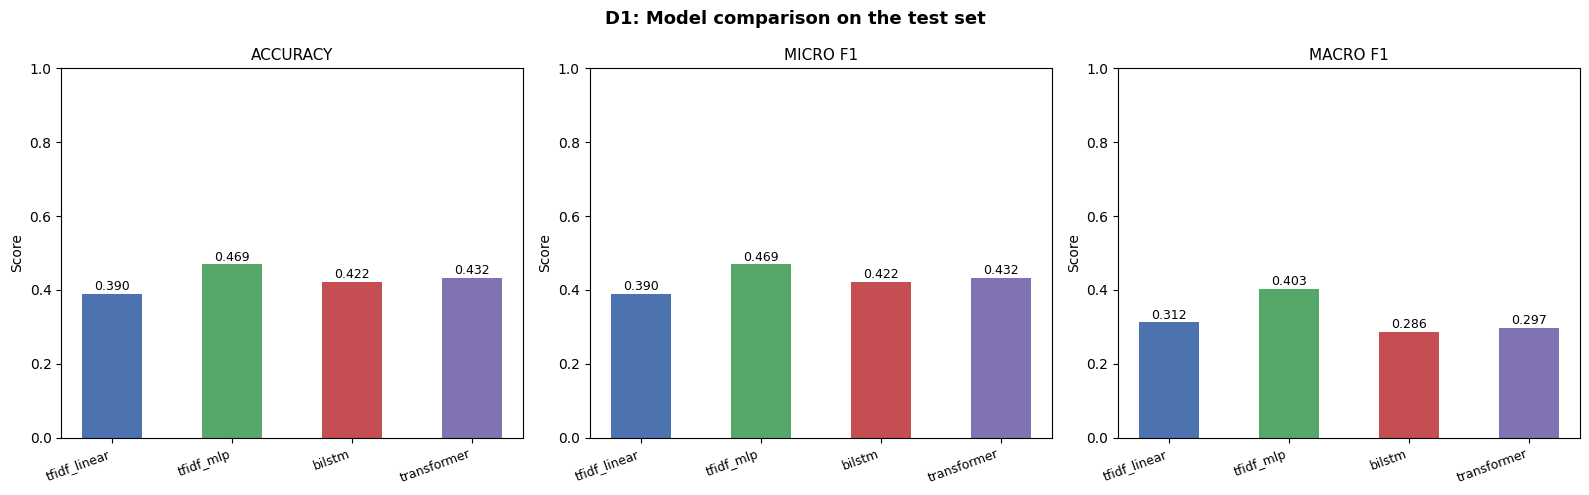

In [14]:
# D1: Accuracy, Micro-F1, Macro-F1 as complexity increases

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('D1: Model comparison on the test set', fontsize=13, fontweight='bold')

model_order = ['tfidf_linear', 'tfidf_mlp', 'bilstm', 'transformer']
palette     = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

for ax, metric in zip(axes, ['accuracy', 'micro_f1', 'macro_f1']):
    data = metrics_df.set_index('model').loc[
        [m for m in model_order if m in metrics_df['model'].values]
    ][metric]
    bars = ax.bar(data.index, data.values, color=palette[:len(data)], width=0.5)
    ax.set_title(metric.replace('_', ' ').upper(), fontsize=11)
    ax.set_ylim(0, 1)
    ax.set_xticklabels(data.index, rotation=20, ha='right', fontsize=9)
    ax.set_ylabel('Score')
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.01,
                f'{bar.get_height():.3f}',
                ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(COMPARISON_PATH, f'{date}_d1_test_metrics.png'), dpi=150)
plt.show()

## Per-class metrics comparison: scatterplot on F1-score
In this section we try to answer the second research question: **is there a relationship between the representativeness of emotions in the dataset and the model's ability to recognize them?**

From the visualizations on the disaggregated metrics, it can be observed that all models struggle to correctly classify the emotions represented.

Although the MLP was able to classify emotions with fewer than 10 samples in the test set, the general trend shows that a relationship exists - even if not strictly linear - between the representativeness of emotions in the dataset and the models' ability to recognize them.

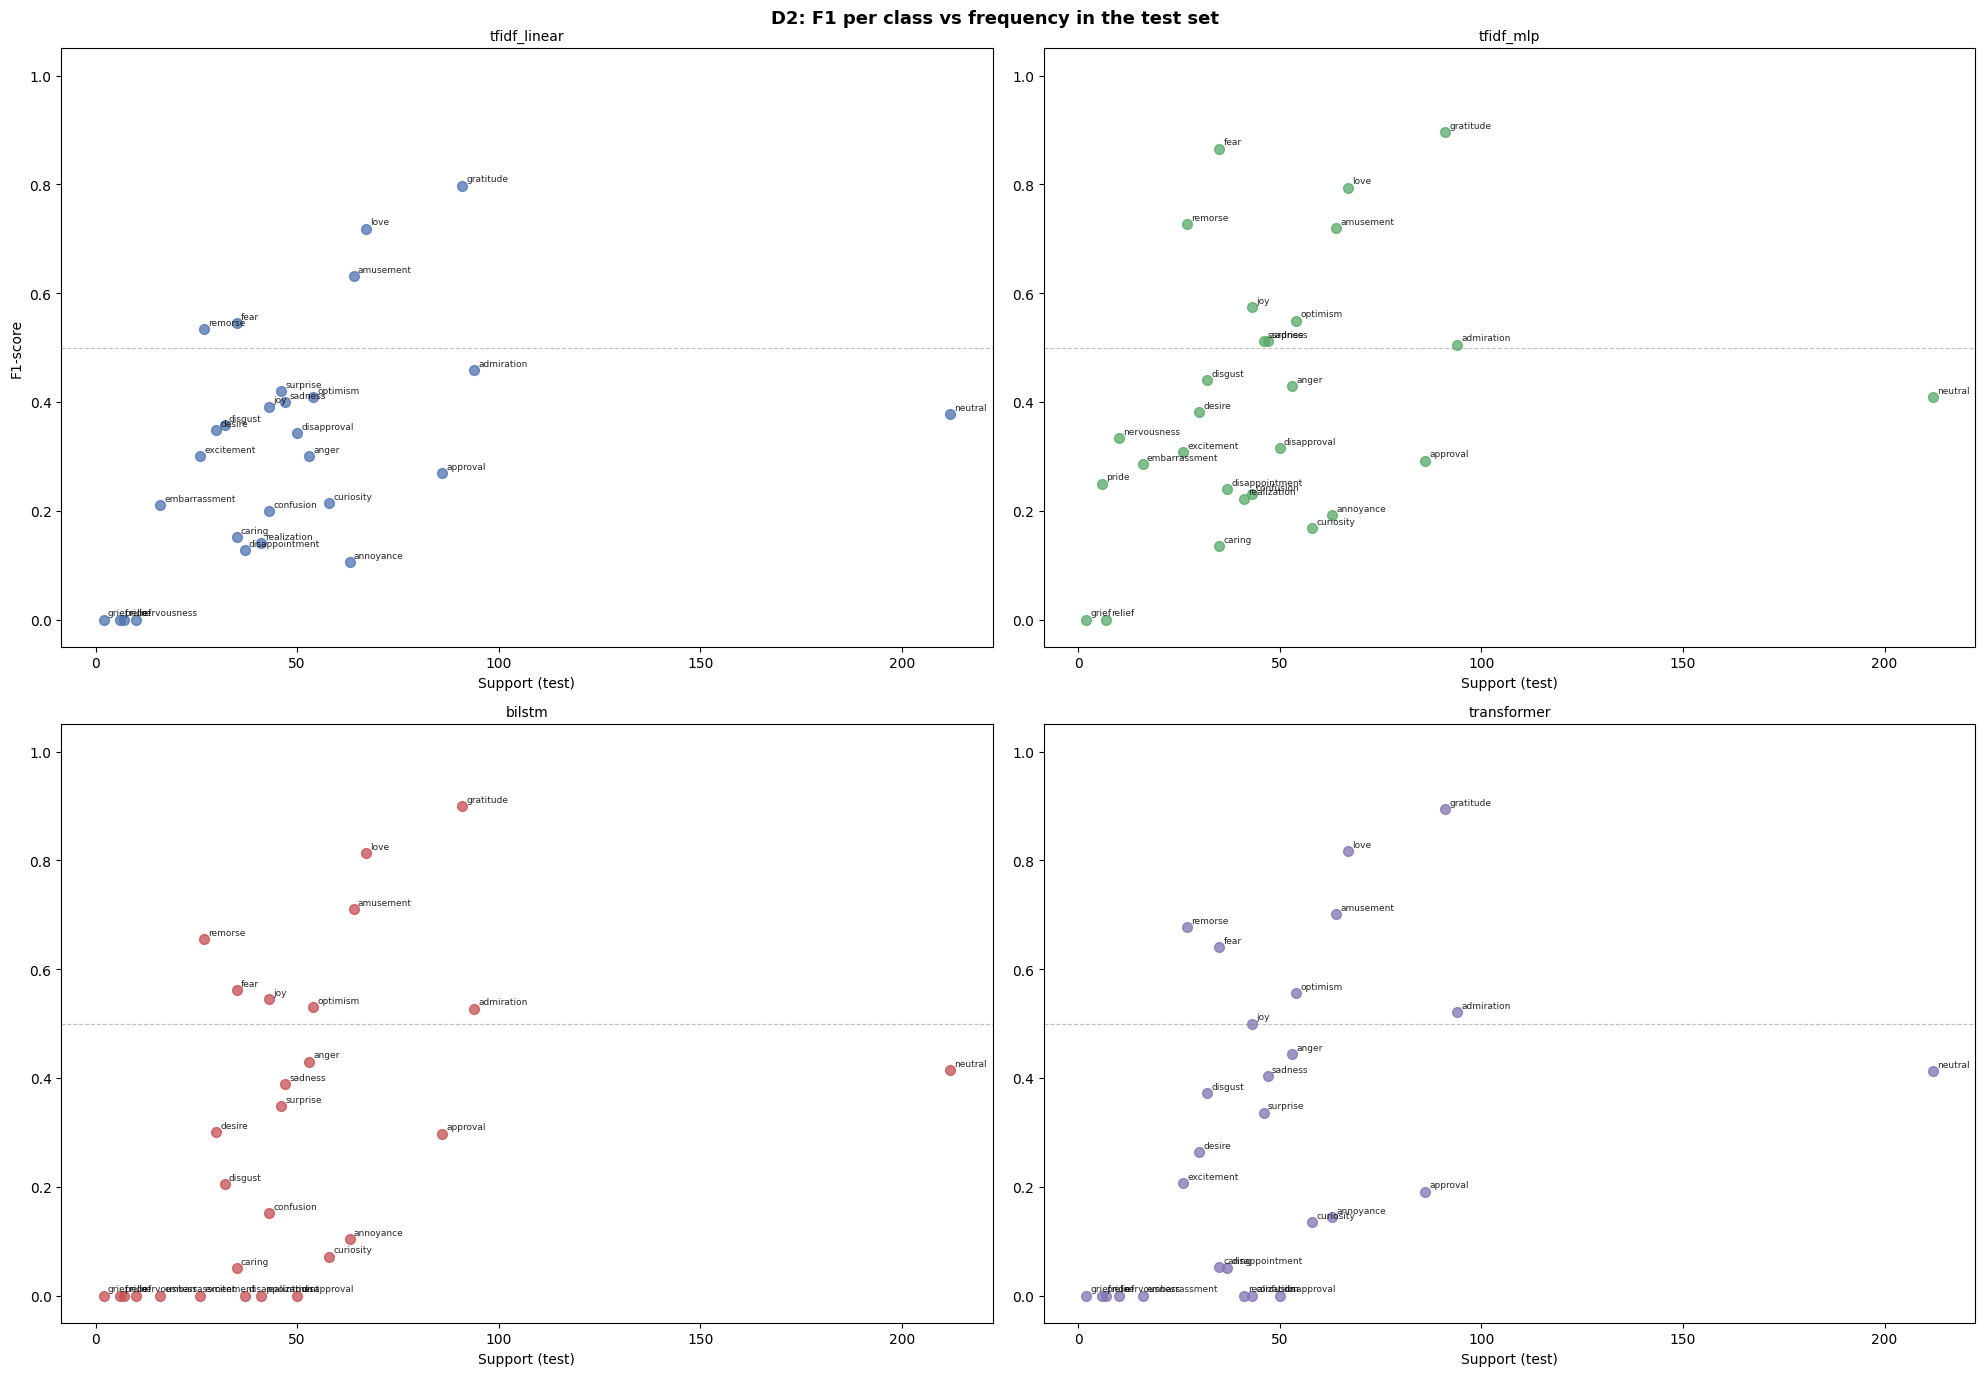

In [15]:
# D2: F1 per class vs frequency in the dataset

# support is the same for all models: same test set
support_order = (
    per_class_df[per_class_df['model'] == 'transformer']
    .sort_values('support')['label']
    .tolist()
)

# scatter F1 vs support for each model
fig, axes = plt.subplots(2, 2, figsize=(20, 14), sharey=False)
fig.suptitle('D2: F1 per class vs frequency in the test set', fontsize=13, fontweight='bold')

for ax, (model_name, color) in zip(axes.flatten(), zip(model_order, palette)):
    df = per_class_df[per_class_df['model'] == model_name]
    ax.scatter(df['support'], df['f1'], color=color, alpha=0.75, s=50)
    for _, r in df.iterrows():
        ax.annotate(r['label'], (r['support'], r['f1']),
                    fontsize=6.5, alpha=0.85,
                    xytext=(3, 3), textcoords='offset points')
    ax.set_title(model_name, fontsize=10)
    ax.set_xlabel('Support (test)')
    ax.set_ylim(-0.05, 1.05)
    ax.axhline(0.5, color='grey', linestyle='--', linewidth=0.8, alpha=0.5)

axes[0, 0].set_ylabel('F1-score')
plt.tight_layout()
plt.savefig(os.path.join(COMPARISON_PATH, f'{date}_d2_f1_vs_support.png'), dpi=300)
plt.show()

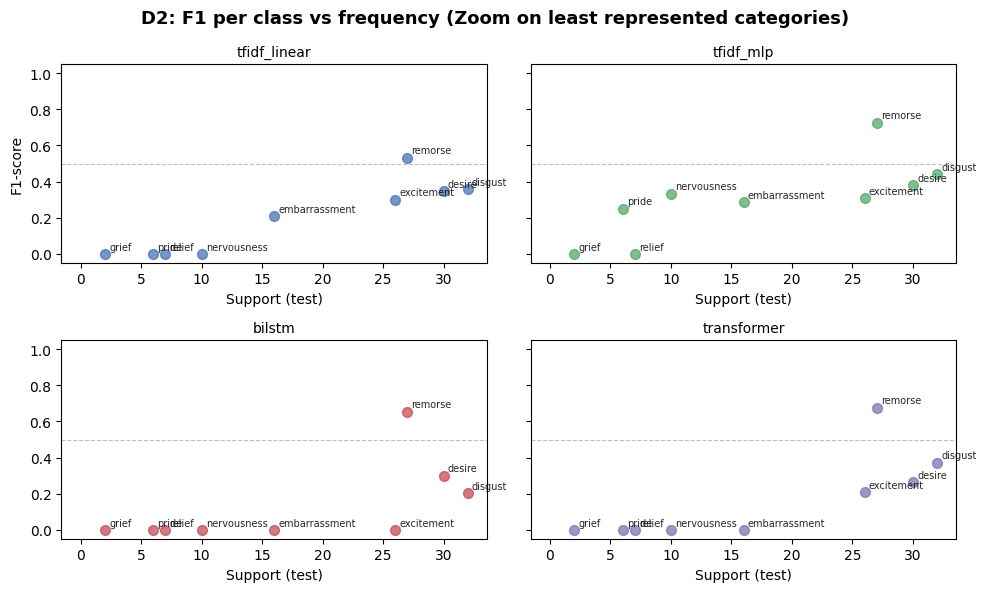

In [16]:
# D2: F1 per class vs frequency in the dataset - zoom

# support is the same for all models, same test set
support_order = (
    per_class_df[per_class_df['model'] == 'transformer']
    .sort_values('support')['label']
    .tolist()
)

# zoom on the 30% least represented categories using percentiles
threshold_support = per_class_df['support'].quantile(0.30)

# scatter F1 vs support for each model - zoomed version
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True, sharex=False)
fig.suptitle('D2: F1 per class vs frequency (Zoom on least represented categories)', fontsize=13, fontweight='bold')

for ax, (model_name, color) in zip(axes.flatten(), zip(model_order, palette)):
    # filter the dataframe to include ONLY categories below the threshold
    df = per_class_df[(per_class_df['model'] == model_name) & (per_class_df['support'] <= threshold_support)]

    ax.scatter(df['support'], df['f1'], color=color, alpha=0.75, s=50)

    for _, r in df.iterrows():
        ax.annotate(r['label'], (r['support'], r['f1']),
                    fontsize=7, alpha=0.85,
                    xytext=(3, 3), textcoords='offset points')

    ax.set_title(model_name, fontsize=10)
    ax.set_xlabel('Support (test)')
    ax.set_ylim(-0.05, 1.05)

    # set x-axis limits leaving a 5% margin on both sides
    ax.set_xlim(-threshold_support * 0.05, threshold_support * 1.05)

    ax.axhline(0.5, color='grey', linestyle='--', linewidth=0.8, alpha=0.5)

axes[0, 0].set_ylabel('F1-score')
plt.tight_layout()

plt.savefig(os.path.join(COMPARISON_PATH, f'{date}_d2_f1_vs_support_zoom.png'), dpi=300)
plt.show()

## Per-class metrics comparison: F1-score heatmap
From this detailed visualization it is possible to notice another trend on emotion classification.

Regardless of the number of samples, some emotions are correctly classified by almost all models, while others are identified almost exclusively by frequency-based models.

The hypothesis, which will be explored in the Explainable AI section, is that simpler models perform better because they rely on tokens that explicitly reference the target emotion.

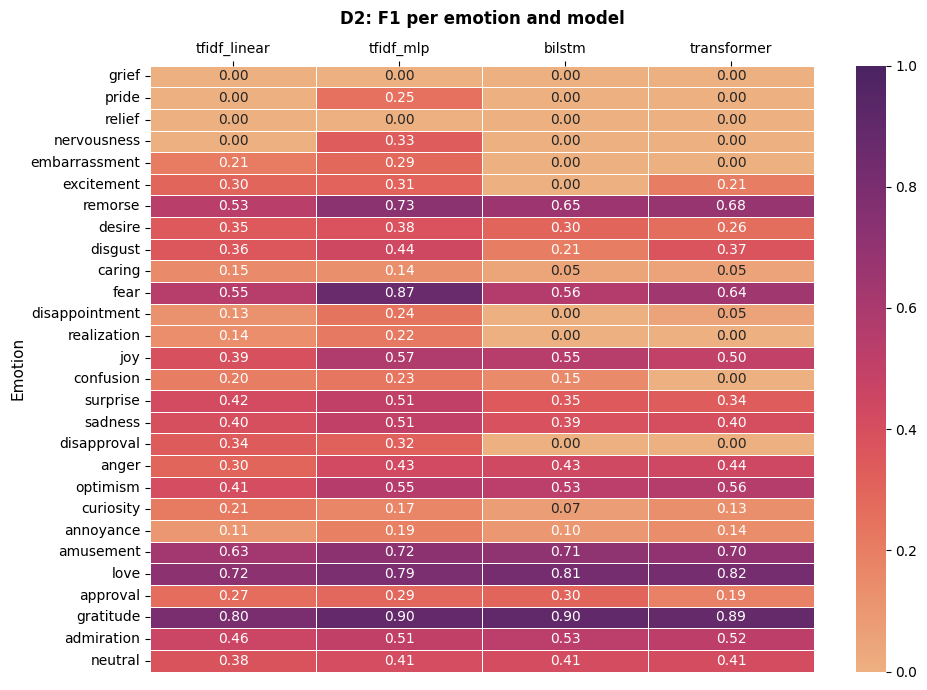

In [17]:
# heatmap F1 per emotion × model, sorted by support
pivot = per_class_df.pivot(index='label', columns='model', values='f1')
pivot = pivot.loc[support_order, model_order]  # sort rows by increasing frequency

# annotate each cell with its value
fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    pivot, annot=True, fmt='.2f', cmap='flare',
    vmin=0, vmax=1, linewidths=0.4, ax=ax
)

# move the x-axis tickers (models) to the top
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')

# rotate model labels to 0 degrees (horizontal) for cleaner reading
plt.xticks(rotation=0)

# the 'pad' parameter spaces the title from the models to avoid overlaps
ax.set_title('D2: F1 per emotion and model',
             fontsize=12, fontweight='bold', pad=30)

ax.set_xlabel('')
ax.set_ylabel('Emotion', fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(COMPARISON_PATH, f'{date}_d2_f1_heatmap_top.png'), dpi=150)
plt.show()

## Per-class metrics comparison: precision vs recall
From the in-depth comparison of the F1-score components it emerges that precision tends to be higher than recall, especially for less frequent emotions.

- **High precision**: this can be interpreted as the overall ability of the models to correctly intercept the class (few false positives)
- **Low recall**: the models are not confident enough during classification, so they miss actually positive cases (many false negatives)

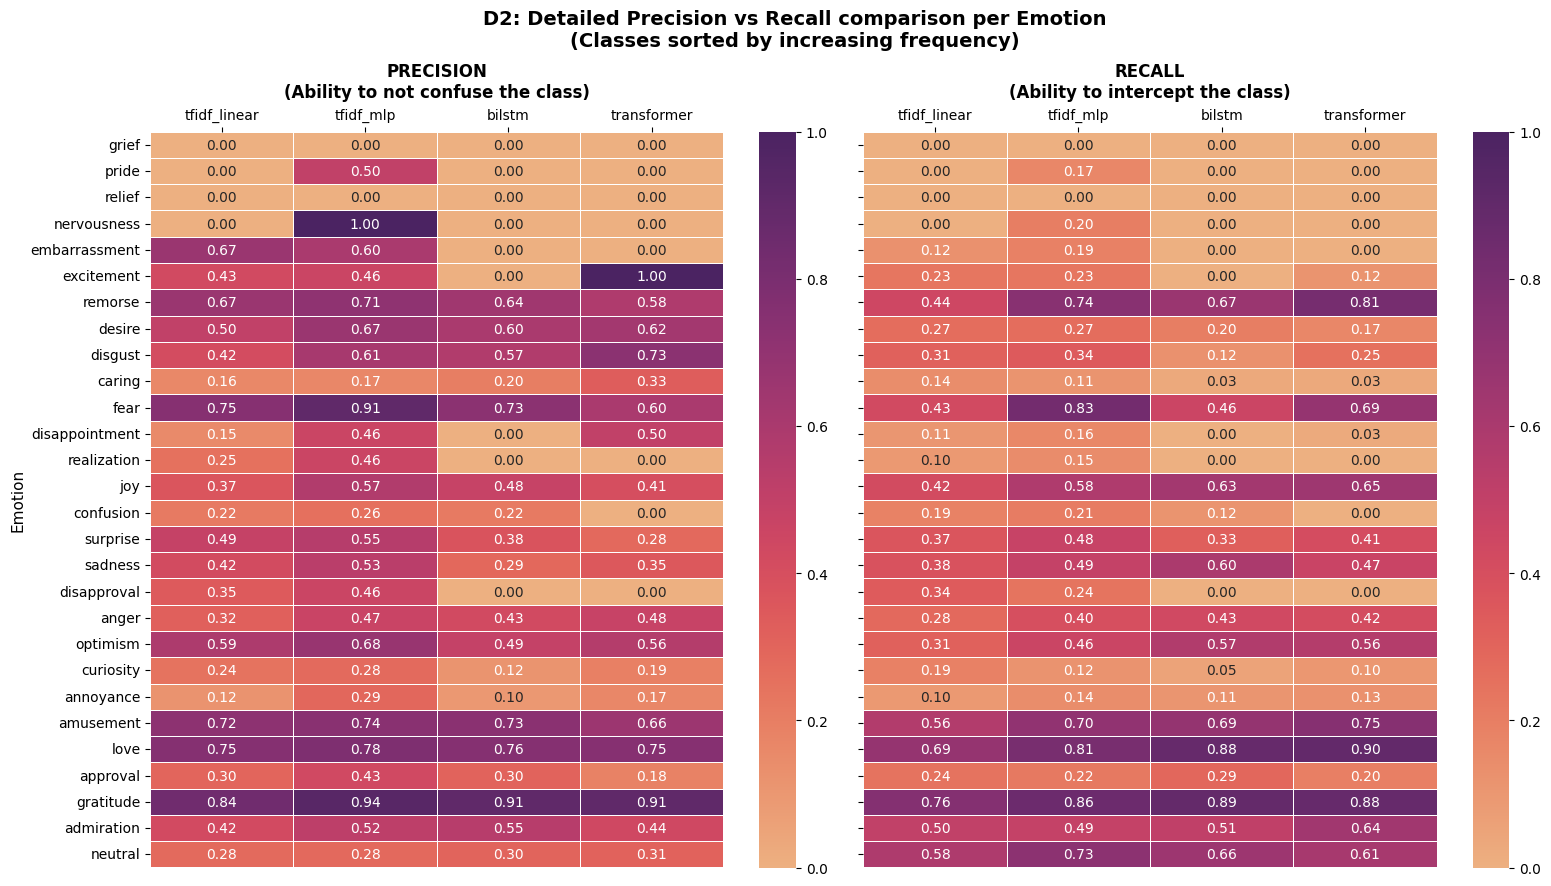

In [18]:
# create the pivots for Precision and Recall
pivot_precision = per_class_df.pivot(index='label', columns='model', values='precision').loc[support_order, model_order]
pivot_recall = per_class_df.pivot(index='label', columns='model', values='recall').loc[support_order, model_order]

# figure with 2 side-by-side subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 9), sharey=True)
fig.suptitle('D2: Detailed Precision vs Recall comparison per Emotion\n(Classes sorted by increasing frequency)',
             fontsize=14, fontweight='bold', y=0.98)

# precision heatmap
sns.heatmap(pivot_precision, annot=True, fmt='.2f', cmap='flare', vmin=0, vmax=1, linewidths=0.4, ax=ax1)
ax1.set_title('PRECISION\n(Ability to not confuse the class)', fontsize=12, pad=25, fontweight='bold')
ax1.xaxis.tick_top()
ax1.xaxis.set_label_position('top')
ax1.set_xlabel('')
ax1.set_ylabel('Emotion', fontsize=11)
ax1.tick_params(axis='x', rotation=0)

# recall heatmap
sns.heatmap(pivot_recall, annot=True, fmt='.2f', cmap='flare', vmin=0, vmax=1, linewidths=0.4, ax=ax2)
ax2.set_title('RECALL\n(Ability to intercept the class)', fontsize=12, pad=25, fontweight='bold')
ax2.xaxis.tick_top()
ax2.xaxis.set_label_position('top')
ax2.set_xlabel('')
ax2.set_ylabel('')  # hide vertical axis label on the second chart since it is shared
ax2.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(COMPARISON_PATH, f'{date}_d2_precision_recall_heatmaps.png'), dpi=150)   # ← see correction #1
plt.show()

## Explainable AI with SHAP
This section addresses the third research question: **how can the model predictions be interpreted?**

To answer this question, the models with the highest and lowest Macro-F1 scores will be compared: the MLP with TF-IDF and the Transformer from scratch, respectively.

Using `shap.GradientExplainer` (which computes Expected Gradients, a SHAP variant based on the integrated-gradients path method) we will investigate which of the two models is more explainable and how the weights attributed to the different tokens differ.

**Note on token coloring**: in the HTML visualizations, only tokens whose normalized attribution exceeds a visibility threshold (`min_visible = 0.05`, applied after a `tanh` normalization anchored to the 95th percentile of `|score|`) are colored. Non-colored tokens are still rendered, and their exact score is available in the `title` attribute (hover with the mouse). This threshold reduces visual noise and highlights only the most influential tokens.

### Gradient-based attribution on the MLP

* **Explainer initialization**: `shap.GradientExplainer` is applied directly to the MLP model. Unlike the Transformer, this is straightforward because the MLP input is the TF-IDF matrix, a continuous and natively differentiable vector space.
* **`explain_mlp`**: extracts the TF-IDF vector of the comment, computes the model prediction, and queries SHAP for the gradient attributions with respect to the target class, returning a flat array of importance scores for each vocabulary term.
* **`visualize_mlp`**: isolates only the words actually present in the analyzed text (`X_tfidf > 0`), maps their numeric indices to the corresponding textual tokens of the TF-IDF vocabulary, and normalizes the scores. It then generates the colored HTML string in **green** for supporting terms and **red** for contrary ones, to visualize the impact of frequentist weights on the dense network's decisions.

In [19]:
# load the integer vocabulary (id -> token)
with open(os.path.join(VECTORIZED_PATH, "vocab_int.json"), "r") as f:
    int_vocab = json.load(f)

# retrieve the embedding layer from the transformer.
# PositionalEmbedding is at index [1], right after the InputLayer [0]
pos_embedding = transformer.layers[1]

# define a sub-model that receives the EMBEDDING (continuous) as input
# and returns the classification scores.
# SHAP requires a continuous input space, so we work on embeddings
# rather than on discrete word IDs.
embedding_input = keras.Input(
    shape=(pos_embedding.seq_length, pos_embedding.embed_dim),
    dtype=tf.float32
)

# rebuild the pipeline, skipping the positional-embedding layer
x = embedding_input
start = False
for layer in transformer.layers:
    if layer == pos_embedding:
        start = True
        continue
    if start:
        x = layer(x)

embedding_model = keras.Model(embedding_input, x)

# build a small background set in the embedding space for SHAP
sample_ids = tf.constant(X_train_int[:200], dtype=tf.int32)
sample_embeddings = pos_embedding(sample_ids).numpy()

# initialize the SHAP GradientExplainer on the continuous embedding space
explainer_trans = shap.GradientExplainer(embedding_model, sample_embeddings)

### Analysis and comparison of test examples
In this section we want to observe how the two models (MLP and Transformer) attribute weights to tokens for label prediction.
The examples to explore belong to:
- **Case 1**: both models perform well (class *gratitude*)
- **Case 2**: MLP beats Transformer
- **Case 3**: Transformer beats MLP
- **Rare classes**: *grief, embarrassment, excitement*

In [20]:
def get_examples_by_label(label_name, n=5):
    """Return the first n test-set indices whose true label matches label_name."""
    label_id = label_to_id[label_name]
    indices = np.where(y_test == label_id)[0]

    return indices[:n]

In [21]:
# MLP EXPLAINER
# background set in the TF-IDF space for SHAP (200 samples, as for the transformer)
_sample_tfidf = X_train_tfidf[:200]
if sp.issparse(_sample_tfidf):
    _sample_tfidf = _sample_tfidf.toarray()
else:
    _sample_tfidf = np.asarray(_sample_tfidf, dtype=np.float32)

# initialize the SHAP GradientExplainer on the MLP model
explainer_mlp = shap.GradientExplainer(tfidf_mlp, _sample_tfidf)
print(f"explainer_mlp initialized - background shape: {_sample_tfidf.shape}")

explainer_mlp initialized - background shape: (200, 2500)


In [22]:
# TF-IDF VOCABULARY

with open(os.path.join(VECTORIZED_PATH, "vocab_tfidf.json"), "r") as f:
    _vt = json.load(f)

# normalize to a {id: token} structure, regardless of the original format
if isinstance(_vt, list):
    tfidf_vocab = _vt                                    # [token0, token1, ...]
elif isinstance(_vt, dict):
    k0 = next(iter(_vt))
    if isinstance(_vt[k0], int):                         # {token: id} → invert
        tfidf_vocab = {v: k for k, v in _vt.items()}
    else:                                                # {id_str: token} -> int keys
        tfidf_vocab = {int(k): v for k, v in _vt.items()}
else:
    raise ValueError(f"Unexpected vocab format: {type(_vt)}")

# sanity check
print(f"tfidf_vocab loaded - type: {type(tfidf_vocab).__name__}, "
      f"size: {len(tfidf_vocab)}, "
      f"sample[0]: {tfidf_vocab[0] if not isinstance(tfidf_vocab, dict) else tfidf_vocab[0]!r}")

tfidf_vocab loaded - type: list, size: 2500, sample[0]: '[UNK]'


In [23]:
# shared helpers

def _to_1d(x):
    """Force an ndarray to 1D, cast to float64 (stable for comparisons)."""
    return np.asarray(x, dtype=np.float64).reshape(-1)

def _extract_attrs(shap_values, pred_class, num_classes):
    """Extract the attribution array of the predicted class from any SHAP output format."""
    if isinstance(shap_values, list):
        raw = shap_values[pred_class]
    else:
        sv = np.asarray(shap_values)
        if sv.ndim >= 2 and sv.shape[-1] == num_classes:      # (..., C)
            raw = sv[..., pred_class]
        elif sv.ndim >= 3 and sv.shape[1] == num_classes:      # (..., C, ...)
            raw = sv[:, pred_class, ...]
        else:
            raw = sv
    attrs = np.asarray(raw)
    if attrs.ndim >= 1 and attrs.shape[0] == 1:                # drop batch dim
        attrs = attrs[0]
    return attrs

def _normalize_for_display(scores):
    """Normalize to [-1, 1] with tanh → amplifies visible differences."""
    s = _to_1d(scores)
    if s.size == 0:
        return s
    scale = np.percentile(np.abs(s), 95)                       # robust to outliers
    if scale <= 1e-12:
        scale = np.abs(s).max()
    if scale <= 1e-12:
        return np.zeros_like(s)
    return np.tanh(s / scale)                                  # key for coloring

def _render_html(tokens, scores, min_visible=0.05):
    """Color the tokens. `title` exposes the score on hover for every token."""
    html = ""
    for token, score in zip(tokens, scores):
        score = float(score)                                   # ensure scalar
        title = f'title="{token}: {score:+.3f}"'
        if abs(score) < min_visible:
            html += f'<span style="padding:2px; margin:1px;" {title}>{token}</span> '
            continue
        s = abs(score)
        if score >= 0:
            red, green = int(255 * (1 - s)), 255
        else:
            red, green = 255, int(255 * (1 - s))
        html += (f'<span style="background-color:rgb({red},{green},0); '
                 f'padding:2px; margin:1px; border-radius:3px;" '
                 f'{title}>{token}</span> ')
    return html


# ============================================================
# TRANSFORMER
# ============================================================
def explain_trans(idx, nsamples=300):
    """Run SHAP GradientExplainer on the Transformer for example idx. Returns token ids, attribution scores, predicted class, and confidence."""
    token_ids = tf.constant(X_test_int[idx:idx+1], dtype=tf.int32)
    embeddings = pos_embedding(token_ids).numpy()
    pred = transformer.predict(token_ids, verbose=0)
    pred_class = int(np.argmax(pred))
    shap_values = explainer_trans.shap_values(embeddings, nsamples=nsamples)
    attrs = _extract_attrs(shap_values, pred_class, NUM_CLASSES)
    token_scores = attrs.sum(axis=-1) if attrs.ndim > 1 else _to_1d(attrs)
    return token_ids[0].numpy(), _to_1d(token_scores), pred_class, float(pred[0][pred_class])

def visualize_trans(idx):
    """Print SHAP attributions for the Transformer on example idx as a colored HTML span display."""
    token_ids, scores, pred_class, confidence = explain_trans(idx)
    mask = token_ids != 0
    token_ids, scores = token_ids[mask], scores[mask]
    if scores.size == 0:
        print("No significant token."); return

    tokens = [int_vocab[i] for i in token_ids]
    scores_norm = _normalize_for_display(scores)

    print(f"Transformer Prediction: {id_to_label[pred_class]} (confidence {confidence * 100:.2f}%)")
    display(HTML(_render_html(tokens, scores_norm)))


# ============================================================
# MLP
# ============================================================
def explain_mlp(idx, nsamples=300):
    """Run SHAP GradientExplainer on the MLP for example idx. Returns attribution scores, predicted class, and confidence."""
    X_tfidf = X_test_tfidf[idx:idx+1]
    pred = tfidf_mlp.predict(X_tfidf, verbose=0)
    pred_class = int(np.argmax(pred))
    shap_values = explainer_mlp.shap_values(X_tfidf, nsamples=nsamples)
    attrs = _extract_attrs(shap_values, pred_class, NUM_CLASSES)
    return _to_1d(attrs), pred_class, float(pred[0][pred_class])

def visualize_mlp(idx):
    """Print SHAP attributions for the MLP on example idx as a colored HTML span display."""
    token_scores, pred_class, confidence = explain_mlp(idx)
    X_tfidf = X_test_tfidf[idx].flatten()
    active_indices = np.where(X_tfidf > 0)[0]
    if active_indices.size == 0:
        print("No active token."); return

    tokens = [tfidf_vocab[i] for i in active_indices]
    scores = _to_1d(token_scores[active_indices])

    scores_norm = _normalize_for_display(scores)

    print(f"MLP Prediction: {id_to_label[pred_class]} (confidence {confidence * 100:.2f}%)")
    display(HTML(_render_html(tokens, scores_norm)))

### Case 1: both models perform well (explicit lexical triggers)
Let's compare the models on the *gratitude* label where both have ~0.90 global F1-score.

The results reveal a clear pattern: both models classify correctly **only when an explicit trigger is present** (e.g. "thank you", "thank"). When the text expresses gratitude through implicit cues or indirect phrasing - such as *"Congratulations mate!!"* or *"Good luck and good on ya"* - both models fail, deviating toward *surprise*, *neutral*, or *optimism*.

This confirms that the models have learned a strong statistical association between the token *thank* and the *gratitude* class, but lack the contextual understanding to infer the same emotion from non-lexical signals. In ambiguous cases, both tend to shift toward a positive but less specific emotion, consistent with their general behavior on majority classes.


In [24]:
print("*** TRANSFORMER vs MLP COMPARISON ON THE GRATITUDE LABEL ***")

for idx in get_examples_by_label("gratitude", n=5):
    print(f"Original Text: {df_test.loc[idx, 'comment_text']}")
    print(f"Real Label: {df_test.loc[idx, 'label']}\n")

    visualize_trans(idx)   # use function for Transformer
    print("-" * 100)
    visualize_mlp(idx)     # use function for the MLP
    print("*" * 100)

*** TRANSFORMER vs MLP COMPARISON ON THE GRATITUDE LABEL ***
Original Text: Congratulations mate!!
Real Label: gratitude

Transformer Prediction: surprise (confidence 44.65%)


----------------------------------------------------------------------------------------------------
MLP Prediction: neutral (confidence 17.94%)


****************************************************************************************************
Original Text: I believe that you can search for providers here. Good luck and good on ya.
Real Label: gratitude

Transformer Prediction: optimism (confidence 61.21%)


----------------------------------------------------------------------------------------------------
MLP Prediction: optimism (confidence 30.60%)


****************************************************************************************************
Original Text: Thank you. ❤️ I really appreciate your comment
Real Label: gratitude

Transformer Prediction: gratitude (confidence 99.01%)


...

****************************************************************************************************
Original Text: Anyway, it's 00:33 am here at the moment, so I'm gonna head to bed. Thank you for reading and good night :)
Real Label: gratitude

Transformer Prediction: gratitude (confidence 98.93%)


----------------------------------------------------------------------------------------------------
MLP Prediction: gratitude (confidence 99.01%)


****************************************************************************************************
Original Text: Thank You, that does seem to be the consensus. 
Real Label: gratitude

Transformer Prediction: gratitude (confidence 99.00%)


----------------------------------------------------------------------------------------------------
MLP Prediction: gratitude (confidence 96.48%)


****************************************************************************************************


### Case 2: MLP beats Transformer

The MLP's strengths in this scenario lie in the native selectivity of TF-IDF encoding. Keeping a clean, isolated statistical weight on the main emotional markers, the frequentist baseline avoids the signal-dispersion problems typical of the Transformer's initial dense representations.

The analysis of the three examples shows the effectiveness of statistical weights versus the criticalities of the continuous positional representation:

1. **First example: distorted sensitivity to irony and polarized terms**

    The MLP correctly extracts the real label *remorse*, while the Transformer collapses onto *joy*.
    Faced with a sarcastic and contradictory expression, the Transformer is fooled by the strong literal polarization of the token "enjoy", missing the necessary hook to contextualize it. Conversely, the MLP does not try to reconstruct the logical link and assigns the prediction based on the dominant weight that the term "sorry" has in the dataset, guessing the correct class.

2. **Second example: over-thinking on secondary nuances**

    The MLP correctly classifies *annoyance*, while the Transformer deviates to *fear*.
    This happens because the MLP immediately values the impact of the term "annoying". The Transformer dilutes the negative components of "annoying" and "terrible", leading the model to prefer the related class of fear, losing the specific activation nuance.

3. **Third example: TF-IDF stability vs dense-vector uncertainty**

    The MLP identifies the real label *fear* with high confidence, while the Transformer fails on *optimism*.
    In this example it is not clear why the Transformer classifies a positive attribute despite the most influential words being "maybe", "worried", and "scare". The MLP exploits the explicit presence of the adverb "scare", whose value in the frequentist dictionary evokes a stable and focused response on the sphere of fear, ensuring a precise classification.

In [25]:
y_pred_trans = np.argmax(y_prob_trans, axis=1)
y_pred_mlp = np.argmax(y_prob_mlp, axis=1)

# array with indices where one model is wrong and the other is right
trans_wrong = np.where((y_pred_trans != y_test) & (y_pred_mlp == y_test))[0]
mlp_wrong   = np.where((y_pred_mlp != y_test) & (y_pred_trans == y_test))[0]

print(f"Wrong labels by Transformer: {len(trans_wrong)}")
print(f"Wrong labels by MLP:         {len(mlp_wrong)}")

Wrong labels by Transformer: 144
Wrong labels by MLP:         93


In [26]:
# indices of the examples to visualize
for idx in [0, 312, 644]:
  print(f"Original text: {df_test.loc[idx, 'comment_text']}")
  print(f"Real label: {df_test.loc[idx, 'label']}\n")

  visualize_trans(idx)  # use function for Transformer
  print("-" * 100)
  visualize_mlp(idx)
  print("*" * 100)

Original text: I'm sorry, I can't hear your useless badgering over me drinking my 38' from a wine bottle and enjoying my extra $200.
Real label: remorse

Transformer Prediction: joy (confidence 30.38%)


----------------------------------------------------------------------------------------------------
MLP Prediction: remorse (confidence 62.95%)


****************************************************************************************************
Original text: Everyone in this video is annoying. This seems like a terrible place to go hang out.
Real label: annoyance

Transformer Prediction: fear (confidence 38.20%)


----------------------------------------------------------------------------------------------------
MLP Prediction: annoyance (confidence 31.58%)


****************************************************************************************************
Original text: Maybe so. Should I try to ask her about it? I'm worried that will only scare her more
Real label: fear

Transformer Prediction: optimism (confidence 52.68%)


----------------------------------------------------------------------------------------------------
MLP Prediction: fear (confidence 83.19%)


****************************************************************************************************


### Case 3: Transformer beats MLP

The main limitations of the MLP that emerge from this comparison concern the inability to modulate emotional terms in slang or ironic contexts and the tendency to dilute the semantic signal in long texts, leading to the choice of the neutral class.

The analysis of the three examples shows the difference between the static frequentist approach and the Transformer's contextual understanding:

1. **First example: semantic misalignment**

    The MLP predicts *disappointment*, while the Transformer identifies *sadness*.
    This happens because the MLP isolates the terms "bad" and "anymore" and, for statistical reasons related to TF-IDF, interprets them as disappointment. Not being able to process the sentence's metaphor, it ignores the impact of words like "die" and "death".

2. **Second example: confusion between similar nuances**

    The MLP predicts *joy* with high confidence, while the Transformer identifies *optimism*.
    The MLP is triggered by the slang formula "happy cake day", unbalancing the prediction toward joy. It lacks the granularity to grasp the real intent. The Transformer recognizes that the core of the message is supported by the verb "hope", preferring optimism over pure joy.

3. **Third example: confusion with contrasting emotions**
    The MLP predicts *neutral* with low confidence, while the Transformer correctly classifies *love*.
    This happens because the MLP focuses on the word "despise", but the token "love" is interpreted as adverse. Identifying inversely heavy weights, the model opts for the neutral option.
    The Transformer captures "love" as a keyword, although it classifies with low confidence.

In [27]:
# indices of the examples to print
for idx in [877, 966, 400]:

  print(f"Original text: {df_test.loc[idx, 'comment_text']}")
  print(f"Real label: {df_test.loc[idx, 'label']}\n")

  visualize_trans(idx)  # Use function for Transformer
  print("-" * 100)
  visualize_mlp(idx)
  print("*" * 100)

Original text: I wanna die I don't wanna live anymore I really wanna die so bad Please return me to the dark abyss I long for death’s sweet kiss
Real label: sadness

Transformer Prediction: sadness (confidence 25.77%)


----------------------------------------------------------------------------------------------------
MLP Prediction: disappointment (confidence 55.98%)


****************************************************************************************************
Original text: Rip I guess.... Hope op does that Also happy cake day!
Real label: optimism

Transformer Prediction: optimism (confidence 36.75%)


----------------------------------------------------------------------------------------------------
MLP Prediction: joy (confidence 80.73%)


****************************************************************************************************
Original text: I equally love and despise them when they talk about a player diving as "flopping"
Real label: love

Transformer Prediction: love (confidence 42.94%)


----------------------------------------------------------------------------------------------------
MLP Prediction: neutral (confidence 22.12%)


****************************************************************************************************


### Case 4: Handling rare classes

In the very-low-support regions of the dataset, the analysis highlights the generalized collapse of both architectures' predictive capability, which tend to choose the majority class *neutral* or confuse labels with related nuances.

The behavior of the models on minority classes highlights two main dynamics:

- **Saturation and default effect (`grief` and `embarrassment`)**: faced with rare emotions such as grief or embarrassment, the models almost always fail because of the scarcity of training examples. The Transformer and the MLP deviate toward *neutral* or collapse onto polarized but wrong classes, such as *curiosity* or *sadness*, showing the inability to map these specific emotional nuances unless guided by a single preponderant keyword.
- **Presence of explicit lexical triggers (`excitement`)**: the only exception to the collapse on rare classes occurs when the text contains a strong, unambiguous term with very high statistical characterization, such as *excited*. In this specific scenario, the MLP guesses the correct label thanks to TF-IDF selectivity, while the Transformer's dense representation tends to dilute itself anyway, shifting toward the related and more represented class of joy.

In [28]:
for emotion_label in ["grief", "embarrassment", "excitement"]:
    for idx in get_examples_by_label(emotion_label, n=3):
        print(f"Original Text: {X_test[idx]}")
        print(f"Real Label: {id_to_label[y_test[idx]]}")
        visualize_trans(idx)
        print("-" * 50)
        visualize_mlp(idx)
        print("*" * 50)

Original Text: death senseless base god forsake
Real Label: grief
Transformer Prediction: sadness (confidence 58.42%)


--------------------------------------------------
MLP Prediction: neutral (confidence 21.66%)


**************************************************
Original Text: rip guy psych
Real Label: grief
Transformer Prediction: neutral (confidence 31.88%)


--------------------------------------------------
MLP Prediction: neutral (confidence 12.62%)


**************************************************
Original Text: know cringing cathartic
Real Label: embarrassment
Transformer Prediction: approval (confidence 21.61%)


...

**************************************************
Original Text: seat young ragewalker
Real Label: excitement
Transformer Prediction: neutral (confidence 45.55%)


--------------------------------------------------
MLP Prediction: neutral (confidence 20.42%)


**************************************************
Original Text: remind iasip
Real Label: excitement
Transformer Prediction: neutral (confidence 35.68%)


--------------------------------------------------
MLP Prediction: realization (confidence 18.33%)


**************************************************


In [29]:
# save SHAP attribution analysis to file
# captures text predictions from all four case studies and writes a
# structured plain-text report to results/comparison/

XAI_REPORT_PATH = os.path.join(COMPARISON_PATH, f"{date}_shap_analysis.txt")


def _top_tokens(tokens, scores_norm, k=5):
    """Return a formatted string of the k tokens with the highest absolute normalised SHAP score."""
    pairs = sorted(zip(tokens, scores_norm), key=lambda x: abs(x[1]), reverse=True)
    return ', '.join(f'{t}({s:+.2f})' for t, s in pairs[:k])


def _run_and_record(indices, section_title):
    """Run both explainers on the given test indices and return a formatted plain-text section."""
    sep = '=' * 70
    lines = [f'\n{sep}', f'  {section_title}', sep]
    for idx in indices:
        # Transformer
        token_ids_t, scores_t, pred_class_t, conf_t = explain_trans(idx)
        mask = token_ids_t != 0
        tokens_t = [int_vocab[i] for i in token_ids_t[mask]]
        scores_norm_t = _normalize_for_display(scores_t[mask])
        # MLP
        raw_scores_m, pred_class_m, conf_m = explain_mlp(idx)
        X_tfidf_row = X_test_tfidf[idx].flatten()
        active = np.where(X_tfidf_row > 0)[0]
        tokens_m = [tfidf_vocab[i] for i in active]
        scores_norm_m = _normalize_for_display(_to_1d(raw_scores_m[active]))
        text_repr = X_test[idx]
        real_label = (
            df_test.loc[idx, 'label'] if idx < len(df_test)
            else id_to_label[int(y_test[idx])]
        )
        block = (
            f'  Text (preprocessed): {text_repr}\n'
            f'  Real label         : {real_label}\n'
            f'  [TRANS] prediction : {id_to_label[pred_class_t]} (conf={conf_t:.4f})\n'
            f'  [TRANS] top tokens : {_top_tokens(tokens_t, scores_norm_t)}\n'
            f'  [MLP]   prediction : {id_to_label[pred_class_m]} (conf={conf_m:.4f})\n'
            f'  [MLP]   top tokens : {_top_tokens(tokens_m, scores_norm_m)}\n'
        )
        lines.append('\n' + block)
    return '\n'.join(lines)


with open(XAI_REPORT_PATH, 'w', encoding='utf-8') as _f:
    sep70 = '=' * 70
    _f.write(f'SHAP Attribution Analysis -- {date}\n')
    _f.write('Models: TF-IDF MLP  vs  Transformer from scratch\n')
    _f.write(f'{sep70}\n')
    _f.write(_run_and_record(
        list(get_examples_by_label('gratitude', n=5)),
        'CASE 1 -- Gratitude (explicit lexical trigger)'))
    _f.write(_run_and_record(
        [0, 312, 644],
        'CASE 2 -- MLP beats Transformer'))
    _f.write(_run_and_record(
        [877, 966, 400],
        'CASE 3 -- Transformer beats MLP'))
    for _emo in ['grief', 'embarrassment', 'excitement']:
        _f.write(_run_and_record(
            list(get_examples_by_label(_emo, n=3)),
            f'CASE 4 -- Rare class: {_emo}'))
    _f.write('\n')

print(f"SHAP analysis saved to {XAI_REPORT_PATH}")


SHAP analysis saved to /content/drive/MyDrive/Behind_GoEmotions/results/comparison/2026-06-06_shap_analysis.txt


## Conclusions and future developments

In conclusion, if the project's goal were deployment in a real context to support critical applications such as *hate speech* detection, toxic content, or signals of emotional distress on social media and online platforms, the optimal methodological choice would inevitably fall on the use of a pre-trained model, capable of transferring a deep and already consolidated linguistic knowledge.

However, having to declare a winner among the models trained from scratch within this experiment, the balance clearly tips in favor of the **Multi-Layer Perceptron (TF-IDF + MLP)**. This approach demonstrated greater overall robustness on imbalanced classes (Macro-F1) and it proves preferable above all in terms of **interpretability**. The possibility of directly mapping the impact of frequentist features through gradient attribution, without the complexity and positional distortions of sequential models' dense representations, makes the MLP a more reliable and easily inspectable choice for short-text classification tasks.